In [1]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\tejas\heart-disease-project
['.ipynb_checkpoints', 'heart_disease_model.pkl', 'labels.csv', 'PRCP-1016-HeartDiseasePred.ipynb', 'values.csv', 'venv']


In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, xgboost
import warnings; warnings.filterwarnings("ignore")

print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("xgboost", xgboost.__version__)

values = pd.read_csv("values.csv")
labels = pd.read_csv("labels.csv")
print(values.shape, labels.shape)
print(values.columns.tolist())
print(labels.columns.tolist())

df = values.merge(labels, on="patient_id")
df.head()


pandas 3.1.1
scikit-learn 1.9.1
xgboost 3.4.1
(180, 14) (180, 2)
['patient_id', 'slope_of_peak_exercise_st_segment', 'thal', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina']
['patient_id', 'heart_disease_present']


,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

values = pd.read_csv("values.csv")
labels = pd.read_csv("labels.csv")
df = values.merge(labels, on="patient_id")
df.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [4]:
print(df.shape)
df.info()
df.describe().T
df.isnull().sum()          # missing values
df.duplicated().sum()      # duplicates
df['heart_disease_present'].value_counts(normalize=True)   # class balance

(180, 15)
<class 'pandas.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    str    
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    str    
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                 

heart_disease_present
0    0.555556
1    0.444444
Name: proportion, dtype: float64

### Data Overview
- The dataset has **180 rows and 15 columns** (patient_id, 13 features, and the target `heart_disease_present`).
- There are **no missing values** in any column, so no imputation is needed.
- 12 columns are integers, 1 is a float (`oldpeak_eq_st_depression`), and 2 are text (`patient_id`, `thal`). `thal` is categorical and will be encoded; `patient_id` is only an identifier and will be dropped.
- **Class distribution:** 55.6% no heart disease and 44.4% heart disease. The classes are fairly balanced, so no resampling is required, but a stratified split is used to preserve the ratio.
- The dataset is small, so cross-validation is used to get reliable performance estimates.

In [5]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate patient_ids:", df['patient_id'].duplicated().sum())
df.describe().T

Duplicate rows: 0
Duplicate patient_ids: 0


,count,mean,std,min,25%,50%,75%,max
slope_of_peak_exercise_st_segment,180.0,1.550000,0.618838,1.0,1.00,1.0,2.00,3.0
resting_blood_pressure,180.0,131.311111,17.010443,94.0,120.00,130.0,140.00,180.0
chest_pain_type,180.0,3.155556,0.938454,1.0,3.00,3.0,4.00,4.0
num_major_vessels,180.0,0.694444,0.969347,0.0,0.00,0.0,1.00,3.0
fasting_blood_sugar_gt_120_mg_per_dl,180.0,0.161111,0.368659,0.0,0.00,0.0,0.00,1.0
resting_ekg_results,180.0,1.050000,0.998742,0.0,0.00,2.0,2.00,2.0
serum_cholesterol_mg_per_dl,180.0,249.211111,52.717969,126.0,213.75,245.5,281.25,564.0
oldpeak_eq_st_depression,180.0,1.010000,1.121357,0.0,0.00,0.8,1.60,6.2
sex,180.0,0.688889,0.464239,0.0,0.00,1.0,1.00,1.0
age,180.0,54.811111,9.334737,29.0,48.00,55.0,62.00,77.0


In [6]:
num_cols = ['age','resting_blood_pressure','serum_cholesterol_mg_per_dl',
            'max_heart_rate_achieved','oldpeak_eq_st_depression']
cat_cols = ['thal','chest_pain_type','num_major_vessels','slope_of_peak_exercise_st_segment',
            'resting_ekg_results','fasting_blood_sugar_gt_120_mg_per_dl','sex','exercise_induced_angina']

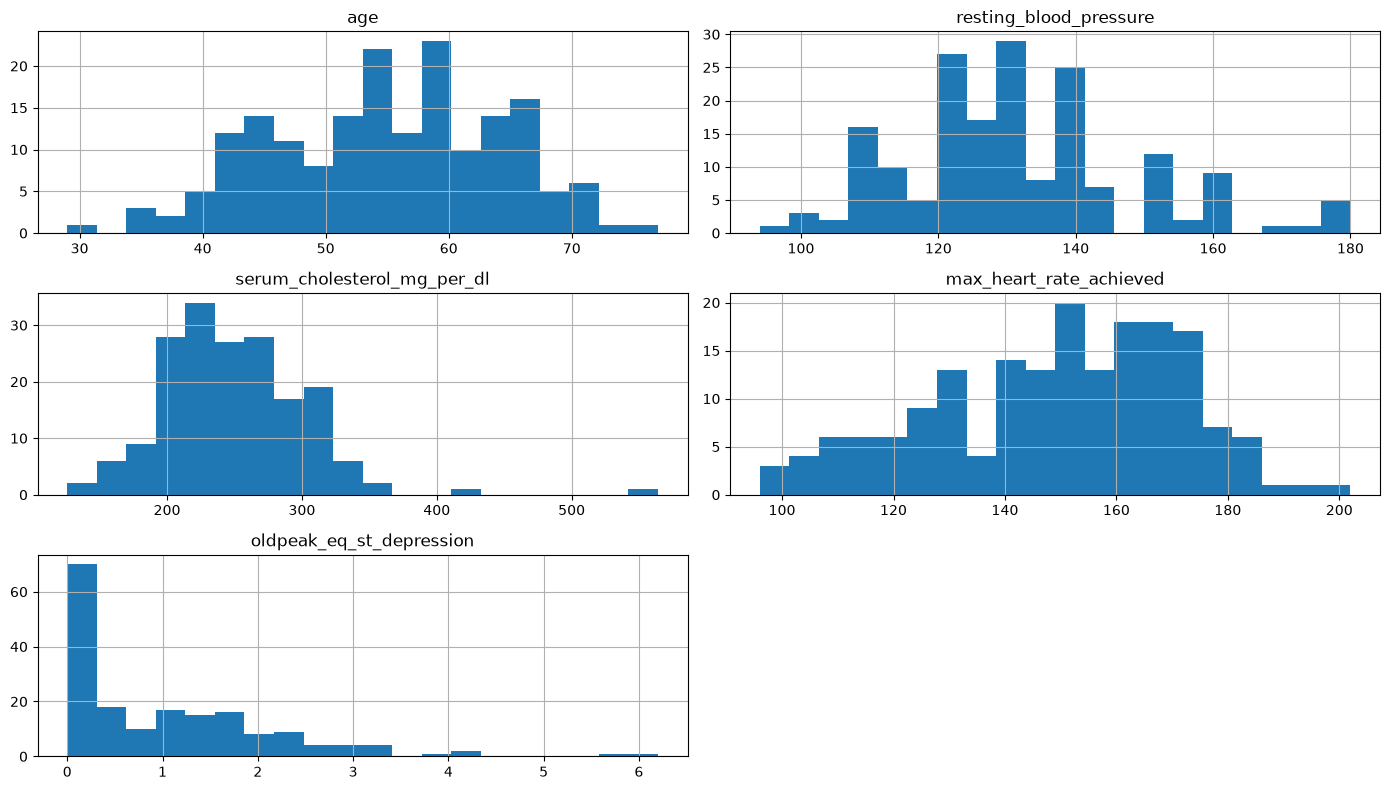

In [7]:
df[num_cols].hist(bins=20, figsize=(14,8))
plt.tight_layout()
plt.show()

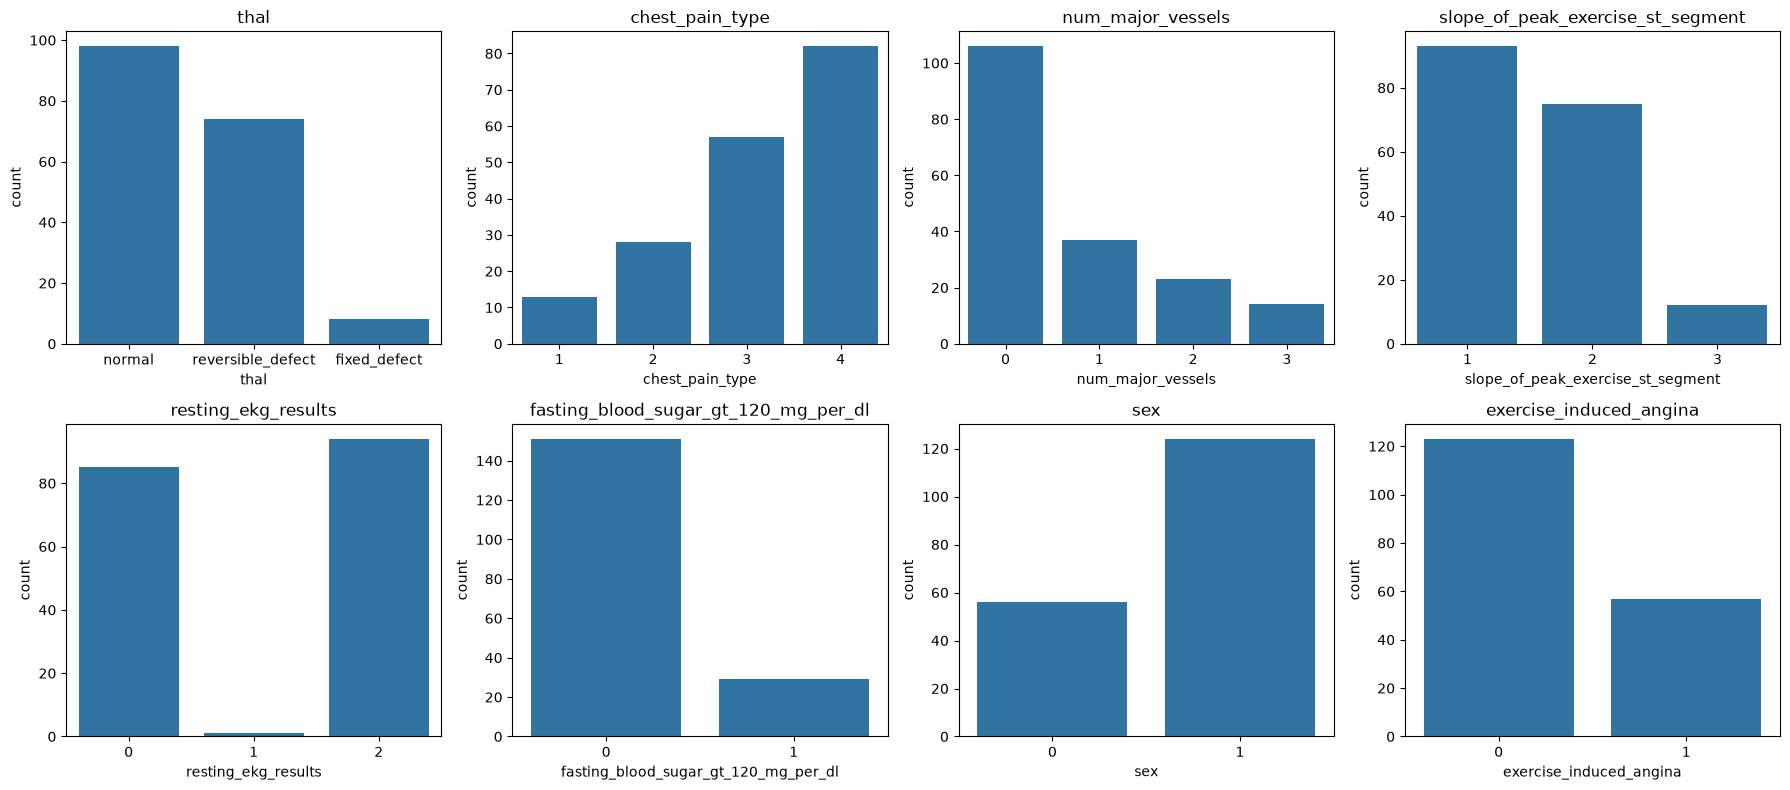

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18,8))
for ax, c in zip(axes.ravel(), cat_cols):
    sns.countplot(x=c, data=df, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

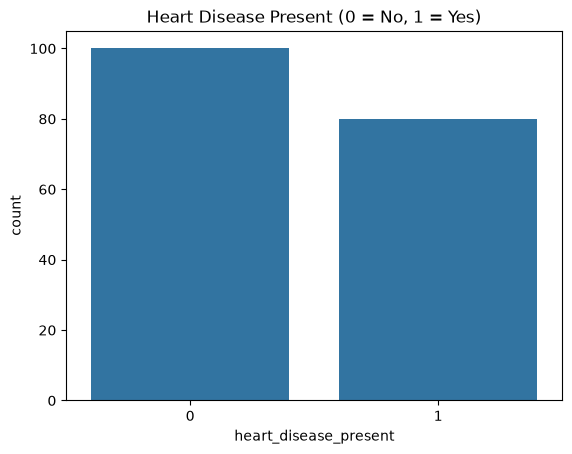

In [9]:
sns.countplot(x='heart_disease_present', data=df)
plt.title("Heart Disease Present (0 = No, 1 = Yes)")
plt.show()

### Univariate Analysis: Observations

**Target variable**
- 100 patients (55.6%) have no heart disease and 80 (44.4%) have it. The classes are fairly balanced.

**Numeric features**
- **Age:** Ranges from about 30 to 77, with most patients between 40 and 70. The distribution is roughly bell-shaped with peaks around 55-60.
- **Resting blood pressure:** Most values fall between 120 and 140 mmHg, with a right tail up to about 180, indicating some hypertensive patients.
- **Serum cholesterol:** Right-skewed, with most values between 200 and 320 mg/dl. A couple of extreme values (around 400 and 560) are outliers.
- **Max heart rate achieved:** Ranges from about 95 to 200 bpm, with most patients between 140 and 180.
- **Oldpeak (ST depression):** Strongly right-skewed, with a large share of patients at 0 and a long tail up to about 6.

**Categorical features**
- **thal:** Normal is the most frequent category, followed by reversible_defect. fixed_defect is rare.
- **chest_pain_type:** Type 4 is the most common, and type 1 is the least common.
- **num_major_vessels:** Most patients have 0 vessels colored; counts decrease as the number of vessels increases.
- **slope_of_peak_exercise_st_segment:** Slopes 1 and 2 dominate; slope 3 is rare.
- **resting_ekg_results:** Values 0 and 2 are common, while value 1 is extremely rare (about 1 patient).
- **fasting_blood_sugar > 120:** Most patients do not have elevated fasting blood sugar.
- **sex:** About two-thirds of patients are male, so the dataset is male-dominated.
- **exercise_induced_angina:** Most patients do not experience exercise-induced angina.

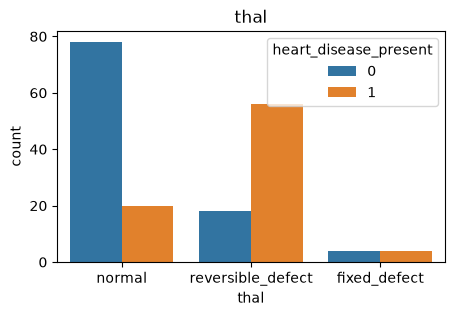

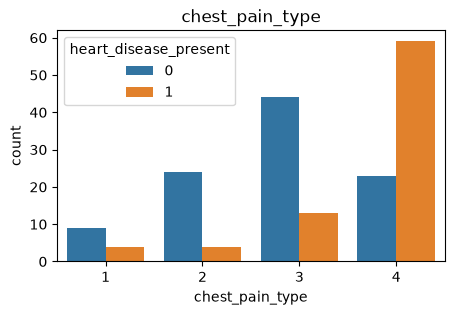

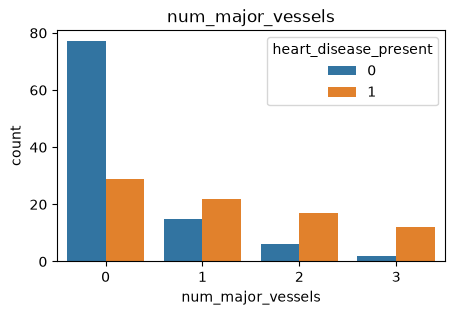

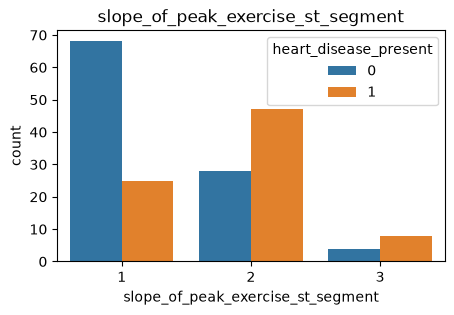

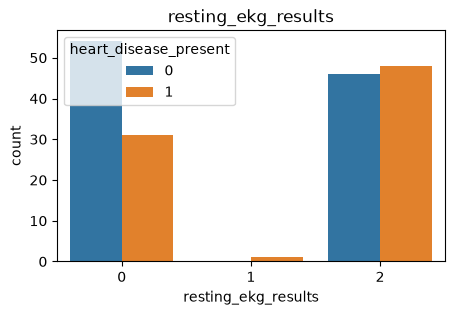

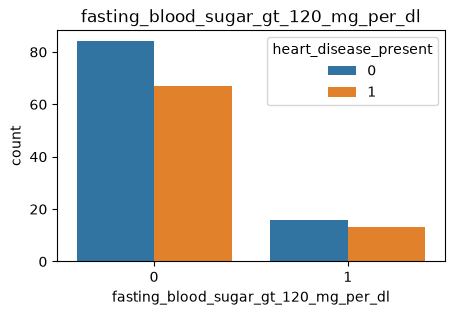

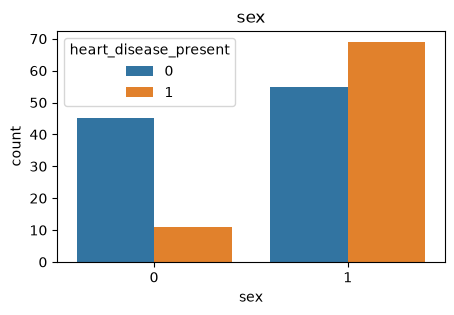

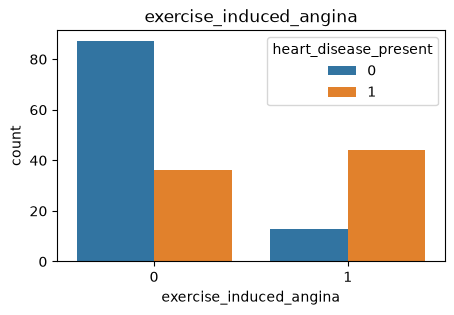

In [10]:
for c in cat_cols:
    plt.figure(figsize=(5,3))
    sns.countplot(x=c, hue='heart_disease_present', data=df)
    plt.title(c)
    plt.show()

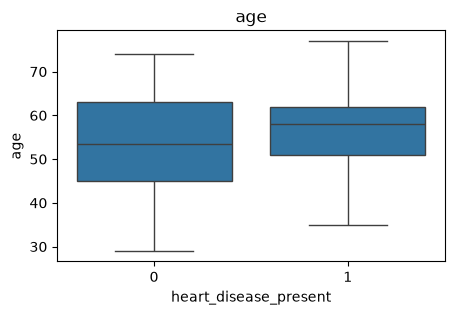

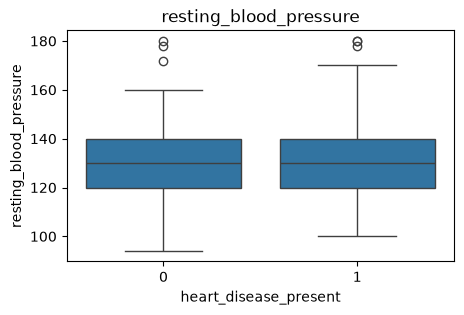

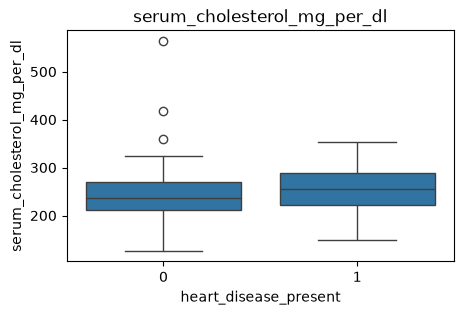

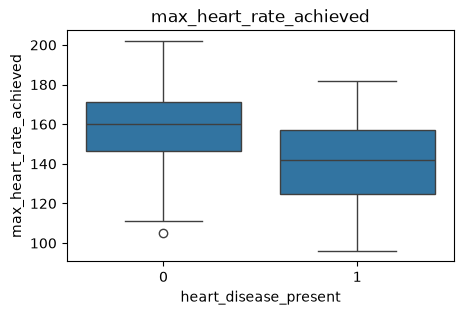

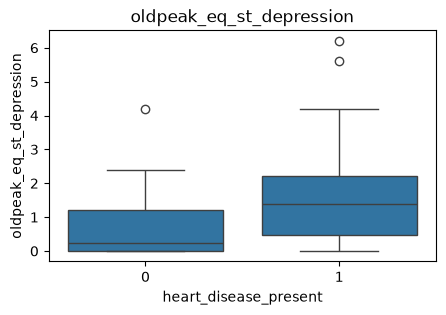

In [11]:
for c in num_cols:
    plt.figure(figsize=(5,3))
    sns.boxplot(x='heart_disease_present', y=c, data=df)
    plt.title(c)
    plt.show()

### Bivariate Analysis: Observations

**Strong indicators of heart disease**
- **thal:** Patients with a reversible defect are mostly diseased (about 56 vs 18), while those with normal results are mostly healthy (about 78 vs 20).
- **chest_pain_type:** Type 4 (asymptomatic) has by far the highest disease count (about 59 vs 23). Types 1-3 are mostly non-diseased.
- **num_major_vessels:** Disease prevalence rises with the number of vessels colored. With 0 vessels most patients are healthy, while from 1 vessel upward disease dominates.
- **exercise_induced_angina:** Patients with exercise-induced angina are much more likely to have disease (about 44 vs 13).
- **slope_of_peak_exercise_st_segment:** Slope 2 is associated with disease, while slope 1 is associated with no disease.
- **sex:** Males show a much higher share of disease (about 56%) than females (about 20%).
- **oldpeak:** Diseased patients have a higher median ST depression (about 1.4 vs 0.2).
- **max_heart_rate_achieved:** Diseased patients reach a lower maximum heart rate (median about 142 vs 160 bpm).

**Weak indicators**
- **age:** Diseased patients are slightly older, but the distributions overlap heavily.
- **serum_cholesterol:** Medians are similar across both groups; the extreme cholesterol outliers belong to the non-disease group.
- **resting_blood_pressure:** Nearly identical distributions in both groups.
- **fasting_blood_sugar > 120:** Disease proportions are similar for both values.
- **resting_ekg_results:** Only a mild difference between values 0 and 2; value 1 has too few patients to judge.

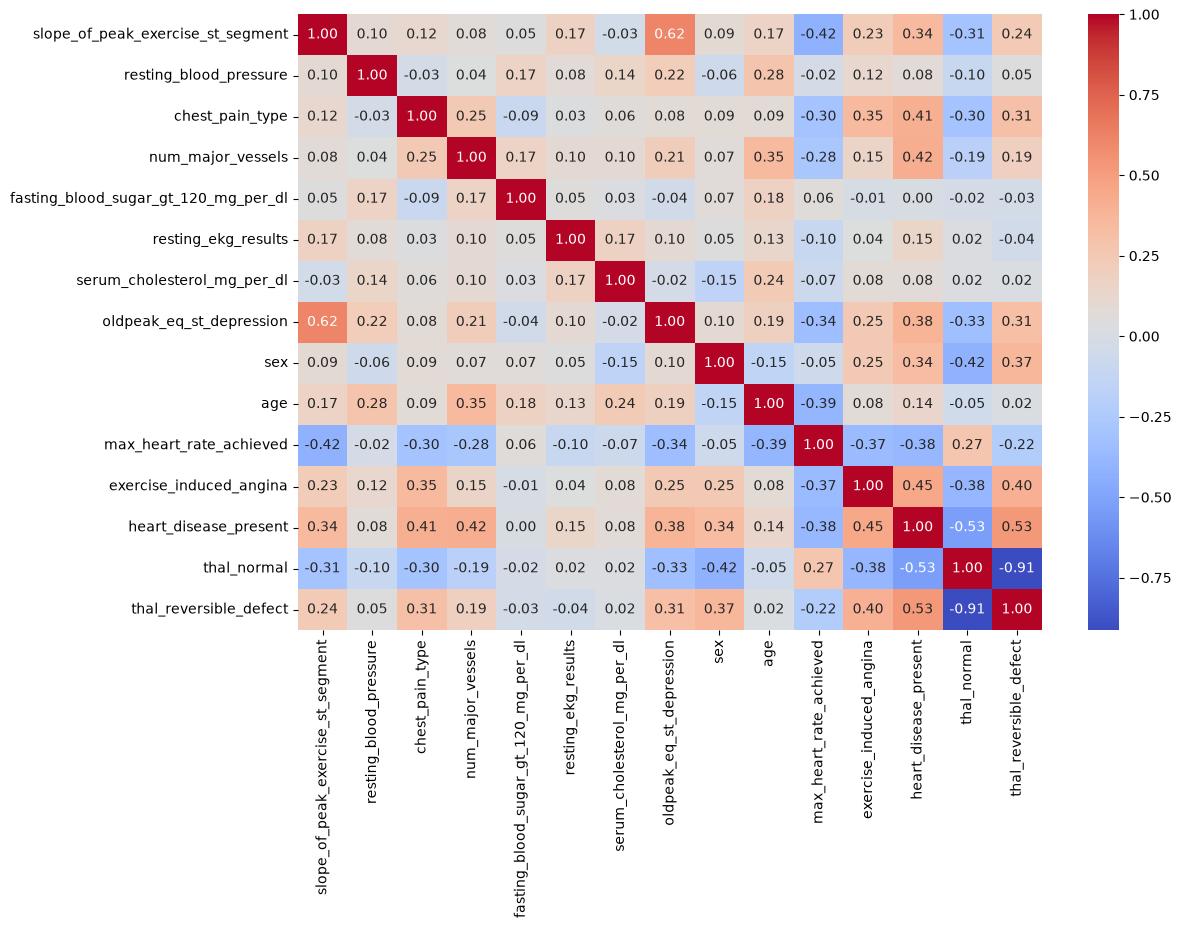

In [12]:
df_enc = pd.get_dummies(df.drop(columns='patient_id'), columns=['thal'], drop_first=True)
plt.figure(figsize=(12,8))
sns.heatmap(df_enc.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [13]:
for c in num_cols:
    q1, q3 = df[c].quantile([.25,.75])
    iqr = q3 - q1
    n = ((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum()
    print(c, "outliers:", n)

age outliers: 0
resting_blood_pressure outliers: 6
serum_cholesterol_mg_per_dl outliers: 2
max_heart_rate_achieved outliers: 0
oldpeak_eq_st_depression outliers: 4


### Outlier Analysis
Using the IQR method, the number of outliers per numeric feature is:
- age: 0
- resting_blood_pressure: 6
- serum_cholesterol_mg_per_dl: 2
- max_heart_rate_achieved: 0
- oldpeak_eq_st_depression: 4

Only 12 outlier values were found in total. They are clinically plausible readings for cardiac patients (for example very high blood pressure or cholesterol), so they carry real information. **Decision: outliers are retained.** StandardScaler is applied to reduce their influence on distance-based and linear models, and tree-based models are not sensitive to them.

### Correlation Analysis
**Relationship with heart disease**
- The strongest positive correlations with heart disease are `thal_reversible_defect` (0.53), `exercise_induced_angina` (0.45), `num_major_vessels` (0.42), `chest_pain_type` (0.41), `oldpeak` (0.38), `sex` (0.34) and `slope_of_peak_exercise_st_segment` (0.34).
- `thal_normal` (-0.53) and `max_heart_rate_achieved` (-0.38) are negatively correlated: patients with normal thal results or a higher maximum heart rate are less likely to have heart disease.
- `age`, `resting_ekg_results`, `resting_blood_pressure`, `serum_cholesterol` and `fasting_blood_sugar` show weak correlation (0.15 or less), consistent with the bivariate plots.

**Relationship between features**
- `thal_normal` and `thal_reversible_defect` are strongly negatively correlated (-0.91) because they are dummy variables of the same column.
- `slope_of_peak_exercise_st_segment` and `oldpeak` are moderately correlated (0.62), as both measure ST-segment behavior.
- No other pair of features is highly correlated, so multicollinearity is not a serious concern.

### Task 1 Summary: Key Insights
1. The dataset has 180 patients, no missing values, and a fairly balanced target (55.6% vs 44.4%).
2. The most important risk indicators are thal result, chest pain type, number of major vessels, exercise-induced angina, ST depression (oldpeak) and maximum heart rate.
3. Males show a higher disease rate than females, but the data is male-dominated (about two-thirds male).
4. Age, resting blood pressure, cholesterol and fasting blood sugar are weak predictors on their own.
5. A few outliers exist but are medically valid, so they were kept.

## Task 2: Model Building

In [14]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df.drop(columns=['patient_id', 'heart_disease_present'])
y = df['heart_disease_present']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)

ohe_cols = ['thal', 'chest_pain_type', 'slope_of_peak_exercise_st_segment', 'resting_ekg_results']
scale_cols = num_cols + ['num_major_vessels']
passthrough_cols = ['sex', 'fasting_blood_sugar_gt_120_mg_per_dl', 'exercise_induced_angina']

preprocess = ColumnTransformer([
    ('ohe', OneHotEncoder(drop='first', handle_unknown='ignore'), ohe_cols),
    ('scale', StandardScaler(), scale_cols),
    ('pass', 'passthrough', passthrough_cols)
])

(144, 13) (36, 13)


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

results = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocess), ('clf', model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    results.append({
        "Model": name,
        "Accuracy": s['test_accuracy'].mean(),
        "Precision": s['test_precision'].mean(),
        "Recall": s['test_recall'].mean(),
        "F1": s['test_f1'].mean(),
        "ROC-AUC": s['test_roc_auc'].mean(),
        "ROC-AUC Std": s['test_roc_auc'].std(),
    })

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC Std
8,XGBoost,0.778,0.765,0.767,0.754,0.883,0.060
0,Logistic Regression,0.834,0.862,0.782,0.807,0.869,0.077
4,Random Forest,0.799,0.816,0.735,0.763,0.869,0.057
5,Gradient Boosting,0.784,0.778,0.751,0.756,0.858,0.040
7,Naive Bayes,0.799,0.792,0.749,0.766,0.858,0.036
2,SVM,0.799,0.825,0.735,0.764,0.856,0.074
6,AdaBoost,0.771,0.780,0.721,0.738,0.836,0.060
1,KNN,0.736,0.745,0.658,0.682,0.811,0.030
3,Decision Tree,0.722,0.678,0.718,0.693,0.721,0.077


### Model Comparison (5-Fold Stratified Cross-Validation on Training Data)
- **XGBoost** achieved the highest ROC-AUC (0.883), while **Logistic Regression** achieved the best accuracy (0.834), precision (0.862), recall (0.782) and F1 (0.807), with a ROC-AUC of 0.869.
- **Random Forest** matched Logistic Regression on ROC-AUC (0.869) with lower variance.
- **Gradient Boosting, Naive Bayes and SVM** performed similarly (ROC-AUC about 0.86).
- **KNN** and **AdaBoost** were weaker, and the single **Decision Tree** performed worst (ROC-AUC 0.721), showing overfitting.
- The differences among the top models are smaller than the fold-to-fold standard deviation (0.04-0.08), so they are statistically close. Given the small dataset, interpretability and stability matter alongside raw scores.
- **Logistic Regression, Random Forest and XGBoost** are selected for hyperparameter tuning.

In [16]:
param_grids = {
    "Logistic Regression": (LogisticRegression(max_iter=1000),
        {'clf__C': [0.01, 0.1, 1, 10], 'clf__penalty': ['l2']}),
    "Random Forest": (RandomForestClassifier(random_state=42),
        {'clf__n_estimators': [100, 200, 300], 'clf__max_depth': [3, 5, None],
         'clf__min_samples_split': [2, 5]}),
    "XGBoost": (XGBClassifier(eval_metric='logloss', random_state=42),
        {'clf__n_estimators': [100, 200], 'clf__max_depth': [2, 3, 4],
         'clf__learning_rate': [0.03, 0.1]}),
}

best_models = {}
for name, (model, grid) in param_grids.items():
    pipe = Pipeline([('prep', preprocess), ('clf', model)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring='roc_auc', n_jobs=-1)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    print(name, gs.best_params_, round(gs.best_score_, 3))

Logistic Regression {'clf__C': 0.1, 'clf__penalty': 'l2'} 0.881
Random Forest {'clf__max_depth': 5, 'clf__min_samples_split': 2, 'clf__n_estimators': 200} 0.883
XGBoost {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 200} 0.886


### Hyperparameter Tuning (GridSearchCV, 5-fold, scoring = ROC-AUC)
| Model | Best parameters | CV ROC-AUC |
|---|---|---|
| Logistic Regression | C=0.1, penalty=l2 | 0.881 |
| Random Forest | max_depth=5, min_samples_split=2, n_estimators=200 | 0.883 |
| XGBoost | learning_rate=0.1, max_depth=3, n_estimators=200 | 0.886 |

Tuning improved all three models slightly (Logistic Regression 0.869 to 0.881, Random Forest 0.869 to 0.883, XGBoost 0.883 to 0.886). The final scores are very close, so the three models are statistically equivalent on this small dataset. They are compared on the held-out test set next.

===== Logistic Regression
              precision    recall  f1-score   support

           0       0.94      0.85      0.89        20
           1       0.83      0.94      0.88        16

    accuracy                           0.89        36
   macro avg       0.89      0.89      0.89        36
weighted avg       0.90      0.89      0.89        36



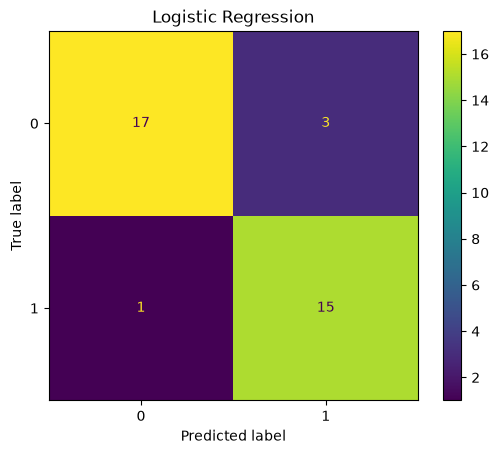

===== Random Forest
              precision    recall  f1-score   support

           0       0.94      0.80      0.86        20
           1       0.79      0.94      0.86        16

    accuracy                           0.86        36
   macro avg       0.87      0.87      0.86        36
weighted avg       0.87      0.86      0.86        36



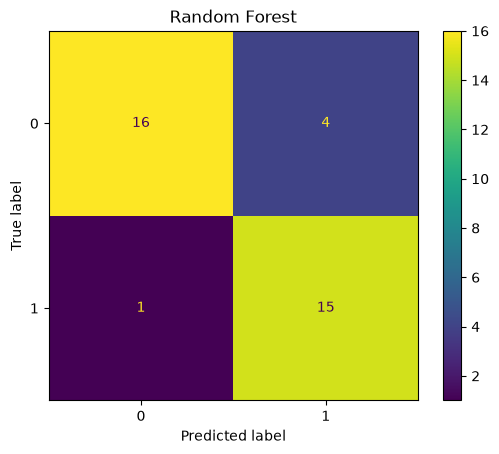

===== XGBoost
              precision    recall  f1-score   support

           0       0.94      0.85      0.89        20
           1       0.83      0.94      0.88        16

    accuracy                           0.89        36
   macro avg       0.89      0.89      0.89        36
weighted avg       0.90      0.89      0.89        36



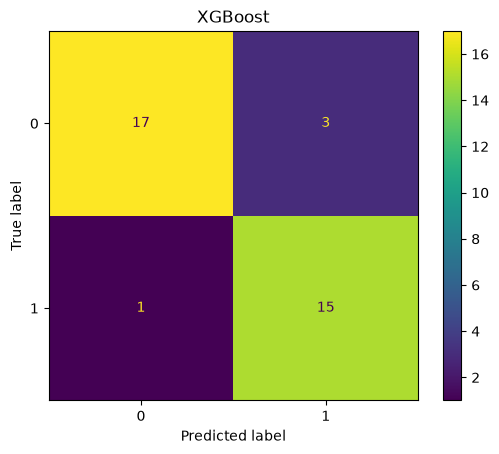

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.889,0.833,0.938,0.882,0.956
1,Random Forest,0.861,0.789,0.938,0.857,0.944
2,XGBoost,0.889,0.833,0.938,0.882,0.944


In [17]:
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, roc_auc_score, accuracy_score,
                             precision_score, recall_score, f1_score)

final_rows = []
for name, m in best_models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    final_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
    print("=====", name)
    print(classification_report(y_test, pred))
    ConfusionMatrixDisplay.from_predictions(y_test, pred)
    plt.title(name)
    plt.show()

final_df = pd.DataFrame(final_rows).round(3)
final_df

### Final Evaluation on Held-Out Test Set (36 patients)
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.889 | 0.833 | 0.938 | 0.882 | 0.956 |
| Random Forest | 0.861 | 0.789 | 0.938 | 0.857 | 0.944 |
| XGBoost | 0.889 | 0.833 | 0.938 | 0.882 | 0.944 |

- All three models detected 15 of the 16 patients with heart disease (recall = 0.938), missing only one. Logistic Regression and XGBoost each produced 3 false positives, while Random Forest produced 4.
- Logistic Regression and XGBoost tied on accuracy, precision, recall and F1, and Logistic Regression had the highest ROC-AUC (0.956).
- The test set contains only 36 patients, so a single prediction changes accuracy by about 2.8 percentage points. The differences between the models are therefore not statistically significant, and the test scores are likely somewhat optimistic compared with the cross-validation scores (about 0.88 ROC-AUC).

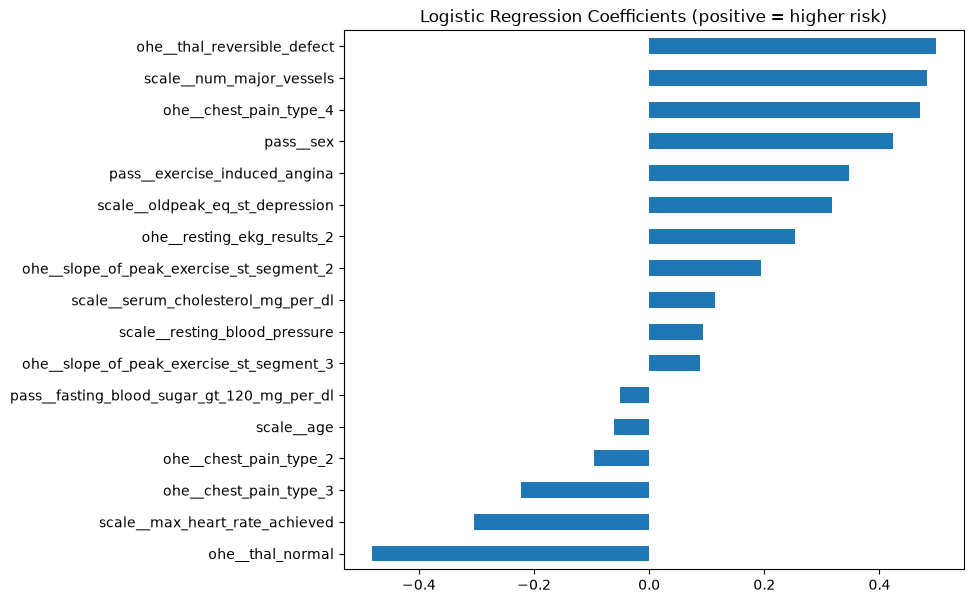

In [18]:
lr = best_models["Logistic Regression"]
names = lr.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=names).sort_values()
coef.plot(kind='barh', figsize=(8,7))
plt.title("Logistic Regression Coefficients (positive = higher risk)")
plt.show()

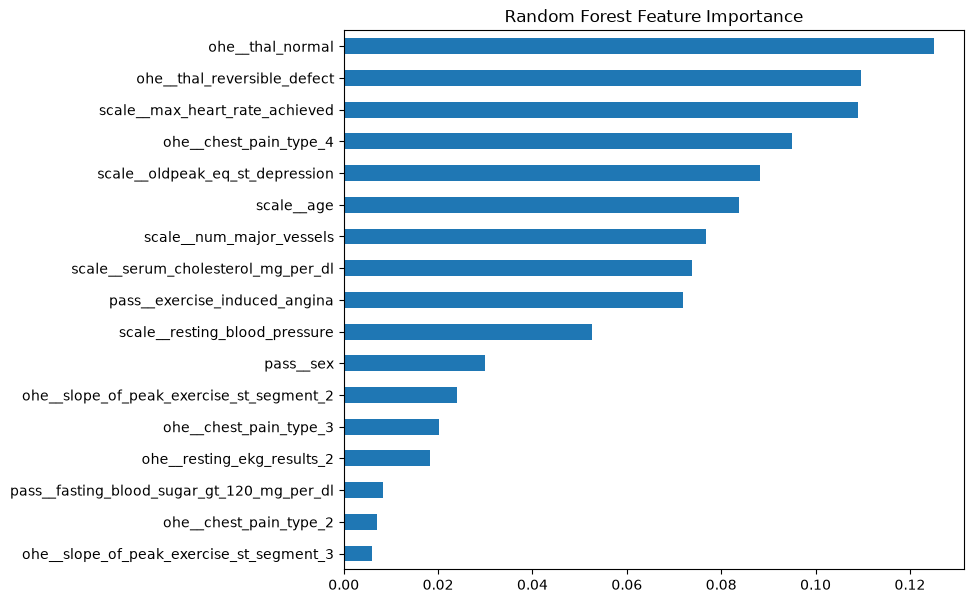

In [19]:
rf = best_models["Random Forest"]
imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=names).sort_values()
imp.plot(kind='barh', figsize=(8,7))
plt.title("Random Forest Feature Importance")
plt.show()

In [20]:
import joblib
joblib.dump(best_models["Logistic Regression"], "heart_disease_model.pkl")

['heart_disease_model.pkl']

### Feature Importance
**Logistic Regression coefficients** (on scaled features): The strongest risk-increasing factors are a reversible thal defect, a higher number of major vessels, chest pain type 4, male sex, exercise-induced angina and a higher ST depression (oldpeak). A normal thal result and a higher maximum heart rate reduce the predicted risk. Age, resting blood pressure, cholesterol and fasting blood sugar have coefficients near zero.

**Random Forest importance:** thal results (normal and reversible defect), maximum heart rate, chest pain type 4 and oldpeak are the most important features.

Both models agree on the key drivers, and these match the correlation and bivariate analysis in Task 1. Random Forest assigns moderate importance to age and cholesterol, which logistic regression and the earlier analysis show to be weak predictors; this is a known tendency of tree models to favor continuous features with many possible split points.

In [21]:
loaded = joblib.load("heart_disease_model.pkl")
sample = X_test.iloc[[0]]
print("Predicted probability of disease:", loaded.predict_proba(sample)[0][1])
print("Actual:", y_test.iloc[0])

Predicted probability of disease: 0.21816559473932398
Actual: 0


## Model Comparison Report

### 1. Approach
Nine classification models were trained inside a scikit-learn Pipeline (encoding and scaling fitted only on training folds, so there is no data leakage). They were compared using 5-fold stratified cross-validation on the training set (144 patients). The three best candidates were tuned with GridSearchCV (scoring = ROC-AUC) and then evaluated once on a held-out test set of 36 patients.

### 2. Cross-Validation Results (before tuning)
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| XGBoost | 0.778 | 0.765 | 0.767 | 0.754 | 0.883 |
| Logistic Regression | 0.834 | 0.862 | 0.782 | 0.807 | 0.869 |
| Random Forest | 0.799 | 0.816 | 0.735 | 0.763 | 0.869 |
| Gradient Boosting | 0.784 | 0.778 | 0.751 | 0.756 | 0.858 |
| Naive Bayes | 0.799 | 0.792 | 0.749 | 0.766 | 0.858 |
| SVM | 0.799 | 0.825 | 0.735 | 0.764 | 0.856 |
| AdaBoost | 0.771 | 0.780 | 0.721 | 0.738 | 0.836 |
| KNN | 0.736 | 0.745 | 0.658 | 0.682 | 0.811 |
| Decision Tree | 0.722 | 0.678 | 0.718 | 0.693 | 0.721 |

### 3. After Hyperparameter Tuning (CV ROC-AUC)
| Model | Best parameters | Before | After |
|---|---|---|---|
| Logistic Regression | C=0.1, penalty=l2 | 0.869 | 0.881 |
| Random Forest | max_depth=5, min_samples_split=2, n_estimators=200 | 0.869 | 0.883 |
| XGBoost | learning_rate=0.1, max_depth=3, n_estimators=200 | 0.883 | 0.886 |

### 4. Final Test-Set Results (36 patients)
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 0.889 | 0.833 | 0.938 | 0.882 | 0.956 |
| Random Forest | 0.861 | 0.789 | 0.938 | 0.857 | 0.944 |
| XGBoost | 0.889 | 0.833 | 0.938 | 0.882 | 0.944 |

### 5. Choice of Metric
In medical screening, a missed patient (false negative) is more dangerous than a false alarm. **Recall** is therefore the most important metric, supported by **ROC-AUC**, which measures how well a model ranks high-risk patients above low-risk ones, and **F1**, which balances precision and recall. Accuracy alone is not sufficient.

### 6. Recommended Model for Production: Logistic Regression
- **Performance:** It tied for the best test accuracy, precision, recall and F1, and had the highest test ROC-AUC (0.956). It detected 15 of 16 patients with heart disease.
- **Interpretability:** Doctors can see how each factor (thal result, number of vessels, chest pain type, etc.) pushes the risk up or down, which builds trust in a clinical setting.
- **Stability:** The complex models did not outperform it significantly, and on only 180 records a simple model has a lower risk of overfitting.
- **Efficiency:** It is very fast to train, deploy and update.

### 7. Limitations
- The dataset is small (180 patients) and the test set only 36, so one patient changes accuracy by about 2.8 percentage points. Differences between the top models are not statistically significant.
- Test scores (ROC-AUC about 0.95) are higher than cross-validation scores (about 0.88), so true performance is likely closer to the cross-validation figures.
- The data is about two-thirds male and comes from a single source, so the model needs external validation on a larger, more diverse population before clinical use.

## Report on Challenges Faced

| # | Challenge | Technique used | Reason |
|---|---|---|---|
| 1 | Features and labels were in two separate files | Merged `values.csv` and `labels.csv` on `patient_id` | To combine each patient's features with their diagnosis |
| 2 | `thal` is text and several other columns are categorical codes | One-hot encoding (`drop='first'`) | Models need numeric input, and one-hot avoids implying a false order |
| 3 | Features are on very different scales (cholesterol ~250, oldpeak ~1) | StandardScaler | Needed for Logistic Regression, SVM and KNN to treat features fairly |
| 4 | Very small dataset (180 rows) | Stratified 5-fold cross-validation | A single split gives unstable, unreliable scores |
| 5 | Risk of data leakage from preprocessing | scikit-learn Pipeline with ColumnTransformer | Scaling and encoding are learned only from training folds |
| 6 | Mild class imbalance (55.6% vs 44.4%) | Stratified split and tracking recall and F1 | Keeps the class ratio in train and test; accuracy alone could mislead. Resampling was not needed |
| 7 | Outliers in blood pressure (6), cholesterol (2) and oldpeak (4) | IQR detection, then kept them | They are clinically plausible readings, and removing them would lose data from sick patients |
| 8 | `resting_ekg_results = 1` has only 1 patient | Kept with one-hot encoding (`handle_unknown='ignore'`) | Dropping it would waste data, and the encoder handles rare categories safely |
| 9 | Decision Tree overfitted (CV ROC-AUC 0.721) | Used ensembles and tuned depth and regularization | Reduces variance and improves generalization |
| 10 | Many models with very close scores | Compared several metrics plus fold standard deviation, and used a held-out test set | Accuracy alone is not enough for medical use, and small gaps are within noise |
| 11 | Test scores looked better than CV scores | Reported both and flagged the test set as small | Avoids overstating real-world performance |
| 12 | Environment issues (pip timeout, typo in command) | Re-ran the install with retries and fixed the command | Internet interruptions caused a failed first install of some libraries |

## Task 3: Suggestions to the Hospital

Based on the analysis and model results, these steps can help the hospital predict heart disease earlier and prevent life-threatening events.

### 1. Use the model as a screening aid
Deploy the Logistic Regression model at registration or triage. From the 13 routine test results, it gives each patient a risk score. The doctor always makes the final decision, and the model only helps prioritize.

### 2. Prioritize high-risk patients using the key risk factors
Our analysis showed the strongest indicators are a **reversible thal defect, number of major vessels, chest pain type 4, exercise-induced angina, higher ST depression (oldpeak), and lower maximum heart rate**. Patients with these findings should be fast-tracked for advanced tests and a cardiologist review.

### 3. Prefer high recall
The model caught 15 of 16 patients with disease. The hospital should accept some false alarms (follow-up tests) rather than miss real cases. A lower decision threshold (for example 0.4) can be used for screening.

### 4. Targeted screening camps
Run regular screening camps for higher-risk groups: men, older adults, and people with chest pain, hypertension, diabetes or high cholesterol.

### 5. Patient awareness and prevention
Educate patients on a healthy diet, regular exercise, quitting smoking and alcohol, stress management, and regular monitoring of blood pressure, sugar and cholesterol. Chest pain, even if mild, should never be ignored.

### 6. Wearables and remote monitoring
Give at-risk patients wearable devices or home monitoring for heart rate and blood pressure, with alerts to doctors when readings are abnormal.

### 7. Improve data collection
The dataset is small and lacks lifestyle information. Collect more patient records and add smoking status, BMI, family history, diet and physical activity. Retrain the model regularly with new data.

### 8. Validate before full use
Test the model on a larger and more diverse group of patients (including more women) at the hospital before relying on it, and monitor its accuracy over time to detect performance drift.

### 9. Data privacy and ethics
Protect patient data under privacy laws, use anonymized data for training, and explain predictions to patients clearly.

### 10. Emergency readiness
Set up fast-track emergency protocols (ECG, cardiac enzymes, ambulance and ICU readiness) for patients flagged as high risk, so treatment starts quickly.

## Conclusion
This project analysed 180 patient records, built and compared nine machine learning models, and tuned the three best. **Logistic Regression** is recommended for production because it matched the best performance (test recall 0.938, ROC-AUC 0.956) while being simple and interpretable. The strongest predictors of heart disease are the thal test result, number of major vessels, chest pain type, exercise-induced angina, ST depression and maximum heart rate. Because the dataset is small, the model should be validated on larger data before clinical use, and it should support, not replace, a doctor's judgment.